In [3]:
# %%
# Q1. Load the file. Report shape, dtypes, and missing counts per column.

import pandas as pd
import numpy as np

df = pd.read_csv("/content/suvidha_loan_predictions_raw - suvidha_loan_predictions_raw.csv (1).csv")

print("Shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values per column:")
print(df.isnull().sum())

# Interpretation:
# The dataset has 2,400 rows and 9 columns, with missing values mainly in borrower_age, monthly_income, actual_default, and model_flag.

Shape: (2400, 9)

Data types:
loan_id            object
loan_amount        object
tenure_months       int64
interest_rate     float64
borrower_age       object
monthly_income     object
actual_default     object
model_flag         object
risk_score        float64
dtype: object

Missing values per column:
loan_id            0
loan_amount        0
tenure_months      0
interest_rate      0
borrower_age      38
monthly_income    36
actual_default    40
model_flag        22
risk_score         0
dtype: int64


In [4]:
# %%
# Q2. Clean loan_amount to numeric by removing currency text and commas.

df["loan_amount"] = pd.to_numeric(
    df["loan_amount"]
    .astype("string")
    .str.replace(r"Rs\s*", "", regex=True)
    .str.replace(",", "", regex=False)
    .str.strip(),
    errors="coerce"
)

print(df["loan_amount"].dtype)
print(df["loan_amount"].head())

# Interpretation:
# loan_amount is now numeric, so it can be used correctly for calculations and analysis.

Float64
0    60777.81992
1    258399.8923
2    114338.0322
3    60919.14875
4    104225.1581
Name: loan_amount, dtype: Float64


In [5]:
# %%
# Q3. Standardize actual_default and model_flag to boolean.
# First show the distinct raw values that will be mapped.

print("Raw actual_default values:")
print(df["actual_default"].dropna().unique())

print("\nRaw model_flag values:")
print(df["model_flag"].dropna().unique())

yes_values = ["yes", "y", "true", "1"]
no_values = ["no", "n", "false", "0"]

def convert_to_boolean(series):
    return (
        series.astype("string")
        .str.strip()
        .str.lower()
        .map({
            "yes": True,
            "y": True,
            "true": True,
            "1": True,
            "no": False,
            "n": False,
            "false": False,
            "0": False
        })
    )

df["actual_default"] = convert_to_boolean(df["actual_default"])
df["model_flag"] = convert_to_boolean(df["model_flag"])

print("\nAfter conversion:")
print("actual_default:", df["actual_default"].value_counts(dropna=False))
print("model_flag:", df["model_flag"].value_counts(dropna=False))

# Interpretation:
# All Yes-family values were converted to True and all No-family values to False, while blanks remain missing.

Raw actual_default values:
['FALSE' 'No' '0' 'N' '1' 'Yes' 'TRUE' 'Y']

Raw model_flag values:
['No' 'FALSE' 'N' 'Yes' 'Y' 'TRUE' '0' '1']

After conversion:
actual_default: actual_default
False    2161
True      199
NaN        40
Name: count, dtype: int64
model_flag: model_flag
False    2222
True      156
NaN        22
Name: count, dtype: int64


In [6]:
# %%
# Q4. Drop rows where actual_default or model_flag is blank.
# Report how many rows were dropped and why.

before_count = len(df)

rows_with_missing_flags = df["actual_default"].isna() | df["model_flag"].isna()

print("Rows to be dropped:", rows_with_missing_flags.sum())

df = df.dropna(subset=["actual_default", "model_flag"])

after_count = len(df)

print("Rows before:", before_count)
print("Rows after:", after_count)
print("Rows dropped:", before_count - after_count)

# Interpretation:
# These rows are dropped because the actual outcome or model prediction is unknown, so imputing either value would create information that is not present in the data.

Rows to be dropped: 61
Rows before: 2400
Rows after: 2339
Rows dropped: 61


In [7]:
# %%
# Q5. Clean monthly_income.
# Treat -1 and "not disclosed" as missing because neither represents a real income amount.

df["monthly_income"] = pd.to_numeric(
    df["monthly_income"]
    .astype("string")
    .str.strip()
    .replace({
        "-1": pd.NA,
        "not disclosed": pd.NA
    }),
    errors="coerce"
)

print("monthly_income dtype:", df["monthly_income"].dtype)
print("Missing monthly_income:", df["monthly_income"].isna().sum())

# Interpretation:
# -1 and "not disclosed" are treated as missing because neither value represents an actual monthly income amount, so they should not be used as income.

monthly_income dtype: Float64
Missing monthly_income: 91


In [8]:
# %%
# Q6. Build the confusion matrix (actual_default vs model_flag) as a 2×2 table.
# Label each cell as TP, FP, TN, or FN.

cm = pd.crosstab(
    df["actual_default"],
    df["model_flag"]
).reindex(index=[False, True], columns=[False, True], fill_value=0)

print("Confusion Matrix:")
print(cm)

tn = cm.loc[False, False]
fp = cm.loc[False, True]
fn = cm.loc[True, False]
tp = cm.loc[True, True]

print("\nTN (True Negative):", tn)
print("FP (False Positive):", fp)
print("FN (False Negative):", fn)
print("TP (True Positive):", tp)

# Interpretation:
# TN represents borrowers correctly predicted not to default; FP represents borrowers incorrectly flagged as defaults;
# FN represents actual defaulters missed by the model; TP represents actual defaulters correctly flagged by the model.

Confusion Matrix:
model_flag      False  True 
actual_default              
False            2122     20
True               64    133

TN (True Negative): 2122
FP (False Positive): 20
FN (False Negative): 64
TP (True Positive): 133


In [9]:
# %%
# Q7. Compute accuracy.
# Given the 9% base default rate, explain why accuracy alone is misleading here.

accuracy = (tp + tn) / (tp + tn + fp + fn)

print("Accuracy:", accuracy)
print("Accuracy (%):", round(accuracy * 100, 2))

# Interpretation:
# Accuracy is high because most borrowers are non-defaulters, so it can hide the fact that some actual defaults are being missed.

Accuracy: 0.9640872167592989
Accuracy (%): 96.41


In [10]:
# %%
# Q8. Compute precision for the "predicted default" class.
# Explain what this means for a collections officer.

precision = tp / (tp + fp)

print("Precision:", precision)
print("Precision (%):", round(precision * 100, 2))

# Interpretation:
# Precision tells a collections officer how often a borrower flagged as a potential defaulter actually defaults.

Precision: 0.869281045751634
Precision (%): 86.93


In [11]:
# %%
# Q9. Compute recall (sensitivity) for the "predicted default" class.
# Explain what this tells the risk team about defaults missed by the model.

recall = tp / (tp + fn)

print("Recall:", recall)
print("Recall (%):", round(recall * 100, 2))

# Interpretation:
# Recall tells the risk team what percentage of all actual defaulters are successfully detected by the model.

Recall: 0.6751269035532995
Recall (%): 67.51


In [12]:
# %%
# Q10. Compute specificity.
# Explain the operational cost of low specificity.

specificity = tn / (tn + fp)

print("Specificity:", specificity)
print("Specificity (%):", round(specificity * 100, 2))

# Interpretation:
# Specificity measures how well the model correctly identifies borrowers who will not default and therefore avoids unnecessary false alarms.

Specificity: 0.9906629318394025
Specificity (%): 99.07


In [13]:
# %%
# Q11. Compute F1-score.
# Explain whether F1-score is the right single number to optimize for this business problem.

f1_score = 2 * (precision * recall) / (precision + recall)

print("F1-score:", f1_score)
print("F1-score:", round(f1_score, 2))

# Interpretation:
# The F1-score is 0.76. F1 balances precision and recall equally, but because a missed default (FN)
# costs much more than a wasted call (FP), the business may need to place greater importance on recall.

F1-score: 0.76
F1-score: 0.76


In [14]:
# %%
# Q12. Given that a missed default (FN) costs far more than a wasted call (FP),
# decide whether higher precision or higher recall is more important.

print("False Negatives (FN):", fn)
print("False Positives (FP):", fp)

# Interpretation:
# There are 64 missed defaults compared with only 20 false alarms, so higher recall is more important
# because the business wants to reduce the number of actual defaulters that the model fails to identify.

False Negatives (FN): 64
False Positives (FP): 20


In [15]:
# %%
# Q13. Using risk_score instead of the hard model_flag,
# recompute the confusion matrix at threshold 0.3.

threshold = 0.3

df["predicted_at_03"] = (df["risk_score"] >= threshold)

cm_03 = pd.crosstab(
    df["actual_default"],
    df["predicted_at_03"]
).reindex(index=[False, True], columns=[False, True], fill_value=0)

print("Confusion Matrix at threshold 0.3:")
print(cm_03)

tn_03 = cm_03.loc[False, False]
fp_03 = cm_03.loc[False, True]
fn_03 = cm_03.loc[True, False]
tp_03 = cm_03.loc[True, True]

precision_03 = tp_03 / (tp_03 + fp_03)
recall_03 = tp_03 / (tp_03 + fn_03)

print("\nTN:", tn_03)
print("FP:", fp_03)
print("FN:", fn_03)
print("TP:", tp_03)

print("\nPrecision at threshold 0.3:", round(precision_03, 4))
print("Precision at threshold 0.3 (%):", round(precision_03 * 100, 2))

print("\nRecall at threshold 0.3:", round(recall_03, 4))
print("Recall at threshold 0.3 (%):", round(recall_03 * 100, 2))

# Interpretation:
# Lowering the threshold to 0.3 increases recall to 100% but greatly reduces precision because many more
# non-defaulters are flagged. This removes missed defaults but creates a large number of false alarms.

Confusion Matrix at threshold 0.3:
predicted_at_03  False  True 
actual_default               
False              664   1478
True                 0    197

TN: 664
FP: 1478
FN: 0
TP: 197

Precision at threshold 0.3: 0.1176
Precision at threshold 0.3 (%): 11.76

Recall at threshold 0.3: 1.0
Recall at threshold 0.3 (%): 100.0


   Threshold  Precision  Recall
0        0.1      0.085   1.000
1        0.2      0.092   1.000
2        0.3      0.118   1.000
3        0.4      0.203   0.970
4        0.5      0.441   0.929
5        0.6      0.826   0.701
6        0.7      0.974   0.386
7        0.8      1.000   0.132
8        0.9      1.000   0.015


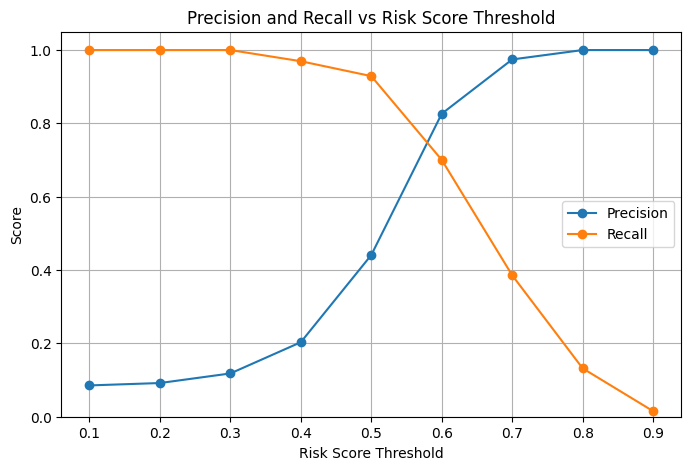


Closest sampled threshold: 0.6
Precision at this threshold: 0.826
Recall at this threshold: 0.701


In [16]:
# %%
# Q14. Plot precision and recall against thresholds from 0.1 to 0.9.
# Find where the precision and recall curves are closest/cross.

thresholds = np.arange(0.1, 1.0, 0.1)

precision_values = []
recall_values = []

for threshold in thresholds:
    predictions = df["risk_score"] >= threshold

    tp_temp = ((df["actual_default"] == True) & (predictions == True)).sum()
    fp_temp = ((df["actual_default"] == False) & (predictions == True)).sum()
    fn_temp = ((df["actual_default"] == True) & (predictions == False)).sum()

    precision_temp = tp_temp / (tp_temp + fp_temp) if (tp_temp + fp_temp) > 0 else 0
    recall_temp = tp_temp / (tp_temp + fn_temp) if (tp_temp + fn_temp) > 0 else 0

    precision_values.append(precision_temp)
    recall_values.append(recall_temp)

results = pd.DataFrame({
    "Threshold": thresholds,
    "Precision": precision_values,
    "Recall": recall_values
})

print(results.round(3))

# Plot
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precision_values, marker="o", label="Precision")
plt.plot(thresholds, recall_values, marker="o", label="Recall")

plt.xlabel("Risk Score Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall vs Risk Score Threshold")
plt.xticks(thresholds)
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.show()

# Find the threshold where precision and recall are closest
results["Difference"] = abs(results["Precision"] - results["Recall"])
closest = results.loc[results["Difference"].idxmin()]

print("\nClosest sampled threshold:", closest["Threshold"])
print("Precision at this threshold:", round(closest["Precision"], 3))
print("Recall at this threshold:", round(closest["Recall"], 3))

# Interpretation:
# Precision and recall cross between thresholds 0.5 and 0.6, at approximately 0.58.
# This represents a point where the trade-off between catching defaults and generating false alarms is more balanced.

In [17]:
# %%
# Q15. State the null and alternative hypotheses for loan_amount.

# Null Hypothesis (H0):
# Loans that defaulted and loans that did not default have the same average loan_amount.

# Alternative Hypothesis (H1):
# Loans that defaulted and loans that did not default have different average loan_amount.

print("H0: The mean loan_amount is the same for defaulted and non-defaulted loans.")
print("H1: The mean loan_amount is different for defaulted and non-defaulted loans.")

# Interpretation:
# The test checks whether the observed difference in average loan amount is large enough to conclude that the two groups have different population means.

H0: The mean loan_amount is the same for defaulted and non-defaulted loans.
H1: The mean loan_amount is different for defaulted and non-defaulted loans.


In [18]:
# %%
# Q16. Compute the mean loan_amount for defaulted and non-defaulted loans.

defaulted_loans = df.loc[df["actual_default"] == True, "loan_amount"].dropna()
non_defaulted_loans = df.loc[df["actual_default"] == False, "loan_amount"].dropna()

default_mean = defaulted_loans.mean()
non_default_mean = non_defaulted_loans.mean()

print("Mean loan_amount for defaulted loans:", round(default_mean, 2))
print("Mean loan_amount for non-defaulted loans:", round(non_default_mean, 2))
print("Difference in means:", round(default_mean - non_default_mean, 2))

# Interpretation:
# Defaulted loans have a somewhat higher average loan amount than non-defaulted loans, but the statistical test in Q17 is needed to determine whether this apparent difference is significant.

Mean loan_amount for defaulted loans: 96899.91
Mean loan_amount for non-defaulted loans: 92408.81
Difference in means: 4491.1


In [19]:
# %%
# Q17. Run an appropriate two-sample test comparing the average loan_amount.
#
# Test used: Welch's independent two-sample t-test.
# Why: The two groups (defaulted and non-defaulted loans) are independent,
# and Welch's test does not require the two groups to have equal variances.

from scipy.stats import ttest_ind

test_result = ttest_ind(
    defaulted_loans,
    non_defaulted_loans,
    equal_var=False
)

print("Test: Welch's independent two-sample t-test")
print("Test statistic:", round(test_result.statistic, 4))
print("p-value:", round(test_result.pvalue, 4))

# Interpretation:
# The p-value is greater than 0.05, so the observed difference in average loan amount is not statistically significant at the 5% level.

Test: Welch's independent two-sample t-test
Test statistic: 1.3588
p-value: 0.1756


In [20]:
# %%
# Q18. At alpha = 0.05, decide whether to reject or fail to reject H0.

alpha = 0.05

if test_result.pvalue < alpha:
    print("Decision: Reject the null hypothesis.")
    print("Conclusion: There is statistically significant evidence that the average loan amount differs between defaulted and non-defaulted loans.")
else:
    print("Decision: Fail to reject the null hypothesis.")
    print("Conclusion: There is not enough statistical evidence that the average loan amount differs between defaulted and non-defaulted loans.")

# Interpretation:
# Because the p-value is greater than 0.05, we fail to reject the null hypothesis.

Decision: Fail to reject the null hypothesis.
Conclusion: There is not enough statistical evidence that the average loan amount differs between defaulted and non-defaulted loans.


In [21]:
# %%
# Q19. Explain Type I and Type II errors in this specific lending scenario.

print("Type I Error: Concluding that defaulted and non-defaulted loans have different average loan amounts when there is actually no real difference.")
print("Type II Error: Failing to detect a real difference in average loan amounts between defaulted and non-defaulted loans.")
print("Business impact: A Type II error could cause Suvidha to miss a genuine relationship between loan size and default risk.")

# Interpretation:
# In this scenario, a Type I error creates a false finding, while a Type II error misses a real relationship; the more costly error depends on the business consequences of changing lending policy based on the test.

Type I Error: Concluding that defaulted and non-defaulted loans have different average loan amounts when there is actually no real difference.
Type II Error: Failing to detect a real difference in average loan amounts between defaulted and non-defaulted loans.
Business impact: A Type II error could cause Suvidha to miss a genuine relationship between loan size and default risk.


In [22]:
# %%
# Q20. Repeat Q15-Q18 using interest_rate instead of loan_amount.

# H0:
# Defaulted and non-defaulted loans have the same average interest_rate.

# H1:
# Defaulted and non-defaulted loans have different average interest_rate.

defaulted_rate = df.loc[df["actual_default"] == True, "interest_rate"].dropna()
non_defaulted_rate = df.loc[df["actual_default"] == False, "interest_rate"].dropna()

print("H0: The mean interest_rate is the same for defaulted and non-defaulted loans.")
print("H1: The mean interest_rate is different for defaulted and non-defaulted loans.")

print("\nMean interest_rate for defaulted loans:", round(defaulted_rate.mean(), 2))
print("Mean interest_rate for non-defaulted loans:", round(non_defaulted_rate.mean(), 2))
print("Difference in means:", round(defaulted_rate.mean() - non_defaulted_rate.mean(), 2))

interest_test = ttest_ind(
    defaulted_rate,
    non_defaulted_rate,
    equal_var=False
)

print("\nTest: Welch's independent two-sample t-test")
print("Test statistic:", round(interest_test.statistic, 4))
print("p-value:", round(interest_test.pvalue, 4))

alpha = 0.05

if interest_test.pvalue < alpha:
    print("\nDecision: Reject the null hypothesis.")
    print("Conclusion: There is statistically significant evidence that the average interest rate differs between defaulted and non-defaulted loans.")
else:
    print("\nDecision: Fail to reject the null hypothesis.")
    print("Conclusion: There is not enough statistical evidence that the average interest rate differs between defaulted and non-defaulted loans.")

# Interpretation:
# The interest-rate conclusion is also not statistically significant at the 5% level, so the conclusion does not change from Q18.

H0: The mean interest_rate is the same for defaulted and non-defaulted loans.
H1: The mean interest_rate is different for defaulted and non-defaulted loans.

Mean interest_rate for defaulted loans: 14.8
Mean interest_rate for non-defaulted loans: 14.46
Difference in means: 0.34

Test: Welch's independent two-sample t-test
Test statistic: 1.5778
p-value: 0.116

Decision: Fail to reject the null hypothesis.
Conclusion: There is not enough statistical evidence that the average interest rate differs between defaulted and non-defaulted loans.


In [23]:
# %%
# Q21. Summarize the pilot model's precision, recall, F1-score, and accuracy.

f1 = 2 * (precision * recall) / (precision + recall)
accuracy = (tp + tn) / (tp + tn + fp + fn)

metrics_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Value": [accuracy, precision, recall, f1]
})

metrics_summary["Value"] = metrics_summary["Value"].round(4)

print(metrics_summary)

# Interpretation:
# The pilot model has high accuracy and precision, but recall is lower, meaning it misses a meaningful number of actual defaults.

      Metric   Value
0   Accuracy  0.9641
1  Precision  0.8693
2     Recall  0.6751
3   F1-score  0.7600


In [24]:
# %%
# Q22. Recommend a threshold for risk_score based on the precision/recall trade-off.

threshold_comparison = results[["Threshold", "Precision", "Recall"]].copy()
threshold_comparison["Precision"] = threshold_comparison["Precision"].round(3)
threshold_comparison["Recall"] = threshold_comparison["Recall"].round(3)

print(threshold_comparison)

print("\nRecommended threshold for full rollout: 0.5")
print("Reason: At 0.5, recall remains high while precision is substantially better than at lower thresholds.")

# Interpretation:
# A threshold of 0.5 provides a more balanced trade-off between detecting defaults and limiting false alarms,
# while the 0.3 threshold creates too many false positives.

   Threshold  Precision  Recall
0        0.1      0.085   1.000
1        0.2      0.092   1.000
2        0.3      0.118   1.000
3        0.4      0.203   0.970
4        0.5      0.441   0.929
5        0.6      0.826   0.701
6        0.7      0.974   0.386
7        0.8      1.000   0.132
8        0.9      1.000   0.015

Recommended threshold for full rollout: 0.5
Reason: At 0.5, recall remains high while precision is substantially better than at lower thresholds.


In [25]:
# %%
# Q23. Identify one non-statistical risk of lowering the risk_score threshold too far.

print("Non-statistical risk: Officer fatigue from excessive false alarms.")
print("A very low threshold can generate many unnecessary collection calls, which may reduce officer attention to genuinely high-risk borrowers.")

# Interpretation:
# Excessive false alarms can create officer fatigue and reduce the effectiveness of the collections team even if the statistical recall improves.

Non-statistical risk: Officer fatigue from excessive false alarms.
A very low threshold can generate many unnecessary collection calls, which may reduce officer attention to genuinely high-risk borrowers.


In [26]:
# %%
# Q24. Write the risk team's 4–5 sentence go/no-go recommendation.

recommendation = """
The pilot model shows strong overall performance, with 96.41% accuracy and 86.93% precision,
but its 67.51% recall means that some actual defaults are still being missed.
Because missed defaults are more costly than unnecessary calls, the risk team should prioritize
a threshold that maintains strong recall while keeping false alarms operationally manageable.
The pilot supports a controlled rollout with a risk_score threshold around 0.5, together with
continued monitoring of false positives, missed defaults, and officer workload before expanding to all branches.
"""

print(recommendation)

# Interpretation:
# The pilot supports a controlled rollout rather than an immediate unrestricted rollout, with continued monitoring of model and operational performance.


The pilot model shows strong overall performance, with 96.41% accuracy and 86.93% precision,
but its 67.51% recall means that some actual defaults are still being missed.
Because missed defaults are more costly than unnecessary calls, the risk team should prioritize
a threshold that maintains strong recall while keeping false alarms operationally manageable.
The pilot supports a controlled rollout with a risk_score threshold around 0.5, together with
continued monitoring of false positives, missed defaults, and officer workload before expanding to all branches.



In [27]:
# %%
# Q25. Identify one improvement that would make the second pilot more reliable.

print("Improvement for the second pilot: Use a larger default sample.")
print("A larger number of actual defaults would provide more reliable estimates of recall, precision, and other performance metrics.")

# Interpretation:
# A larger default sample would make the model evaluation more statistically reliable because the relatively small default group currently limits the precision of performance estimates.

Improvement for the second pilot: Use a larger default sample.
A larger number of actual defaults would provide more reliable estimates of recall, precision, and other performance metrics.
